In [95]:
import sys
# from opentrons import protocol_api, execute, simulate
# from opentrons.types import Location, Point
import pandas as pd
import numpy as np
import random
import requests
import ast  # safer than eval
from pyDOE import lhs
import random
import matplotlib.pyplot as plt

import os
import cv2
import json
import seaborn as sns

import asyncio
import websockets
import base64
from PIL import Image as PILImage, ImageDraw
from IPython.display import display, Image as IPythonImage
from ipywidgets import interact, IntSlider, fixed
from IPython.display import display, HTML
from color_mixing import GaussianProcess, BayesianOptimization

# Calibrate Image


On raspberry pi terminal, run:
```
python3 websocket_server.py
```

To focus the camera, Open a new terminal and enter:
```
libcamera-still -t 0 --autofocus-mode manual --lens-position 5 --tuning-file /usr/share/libcamera/ipa/vc4/imx219_af.json
```

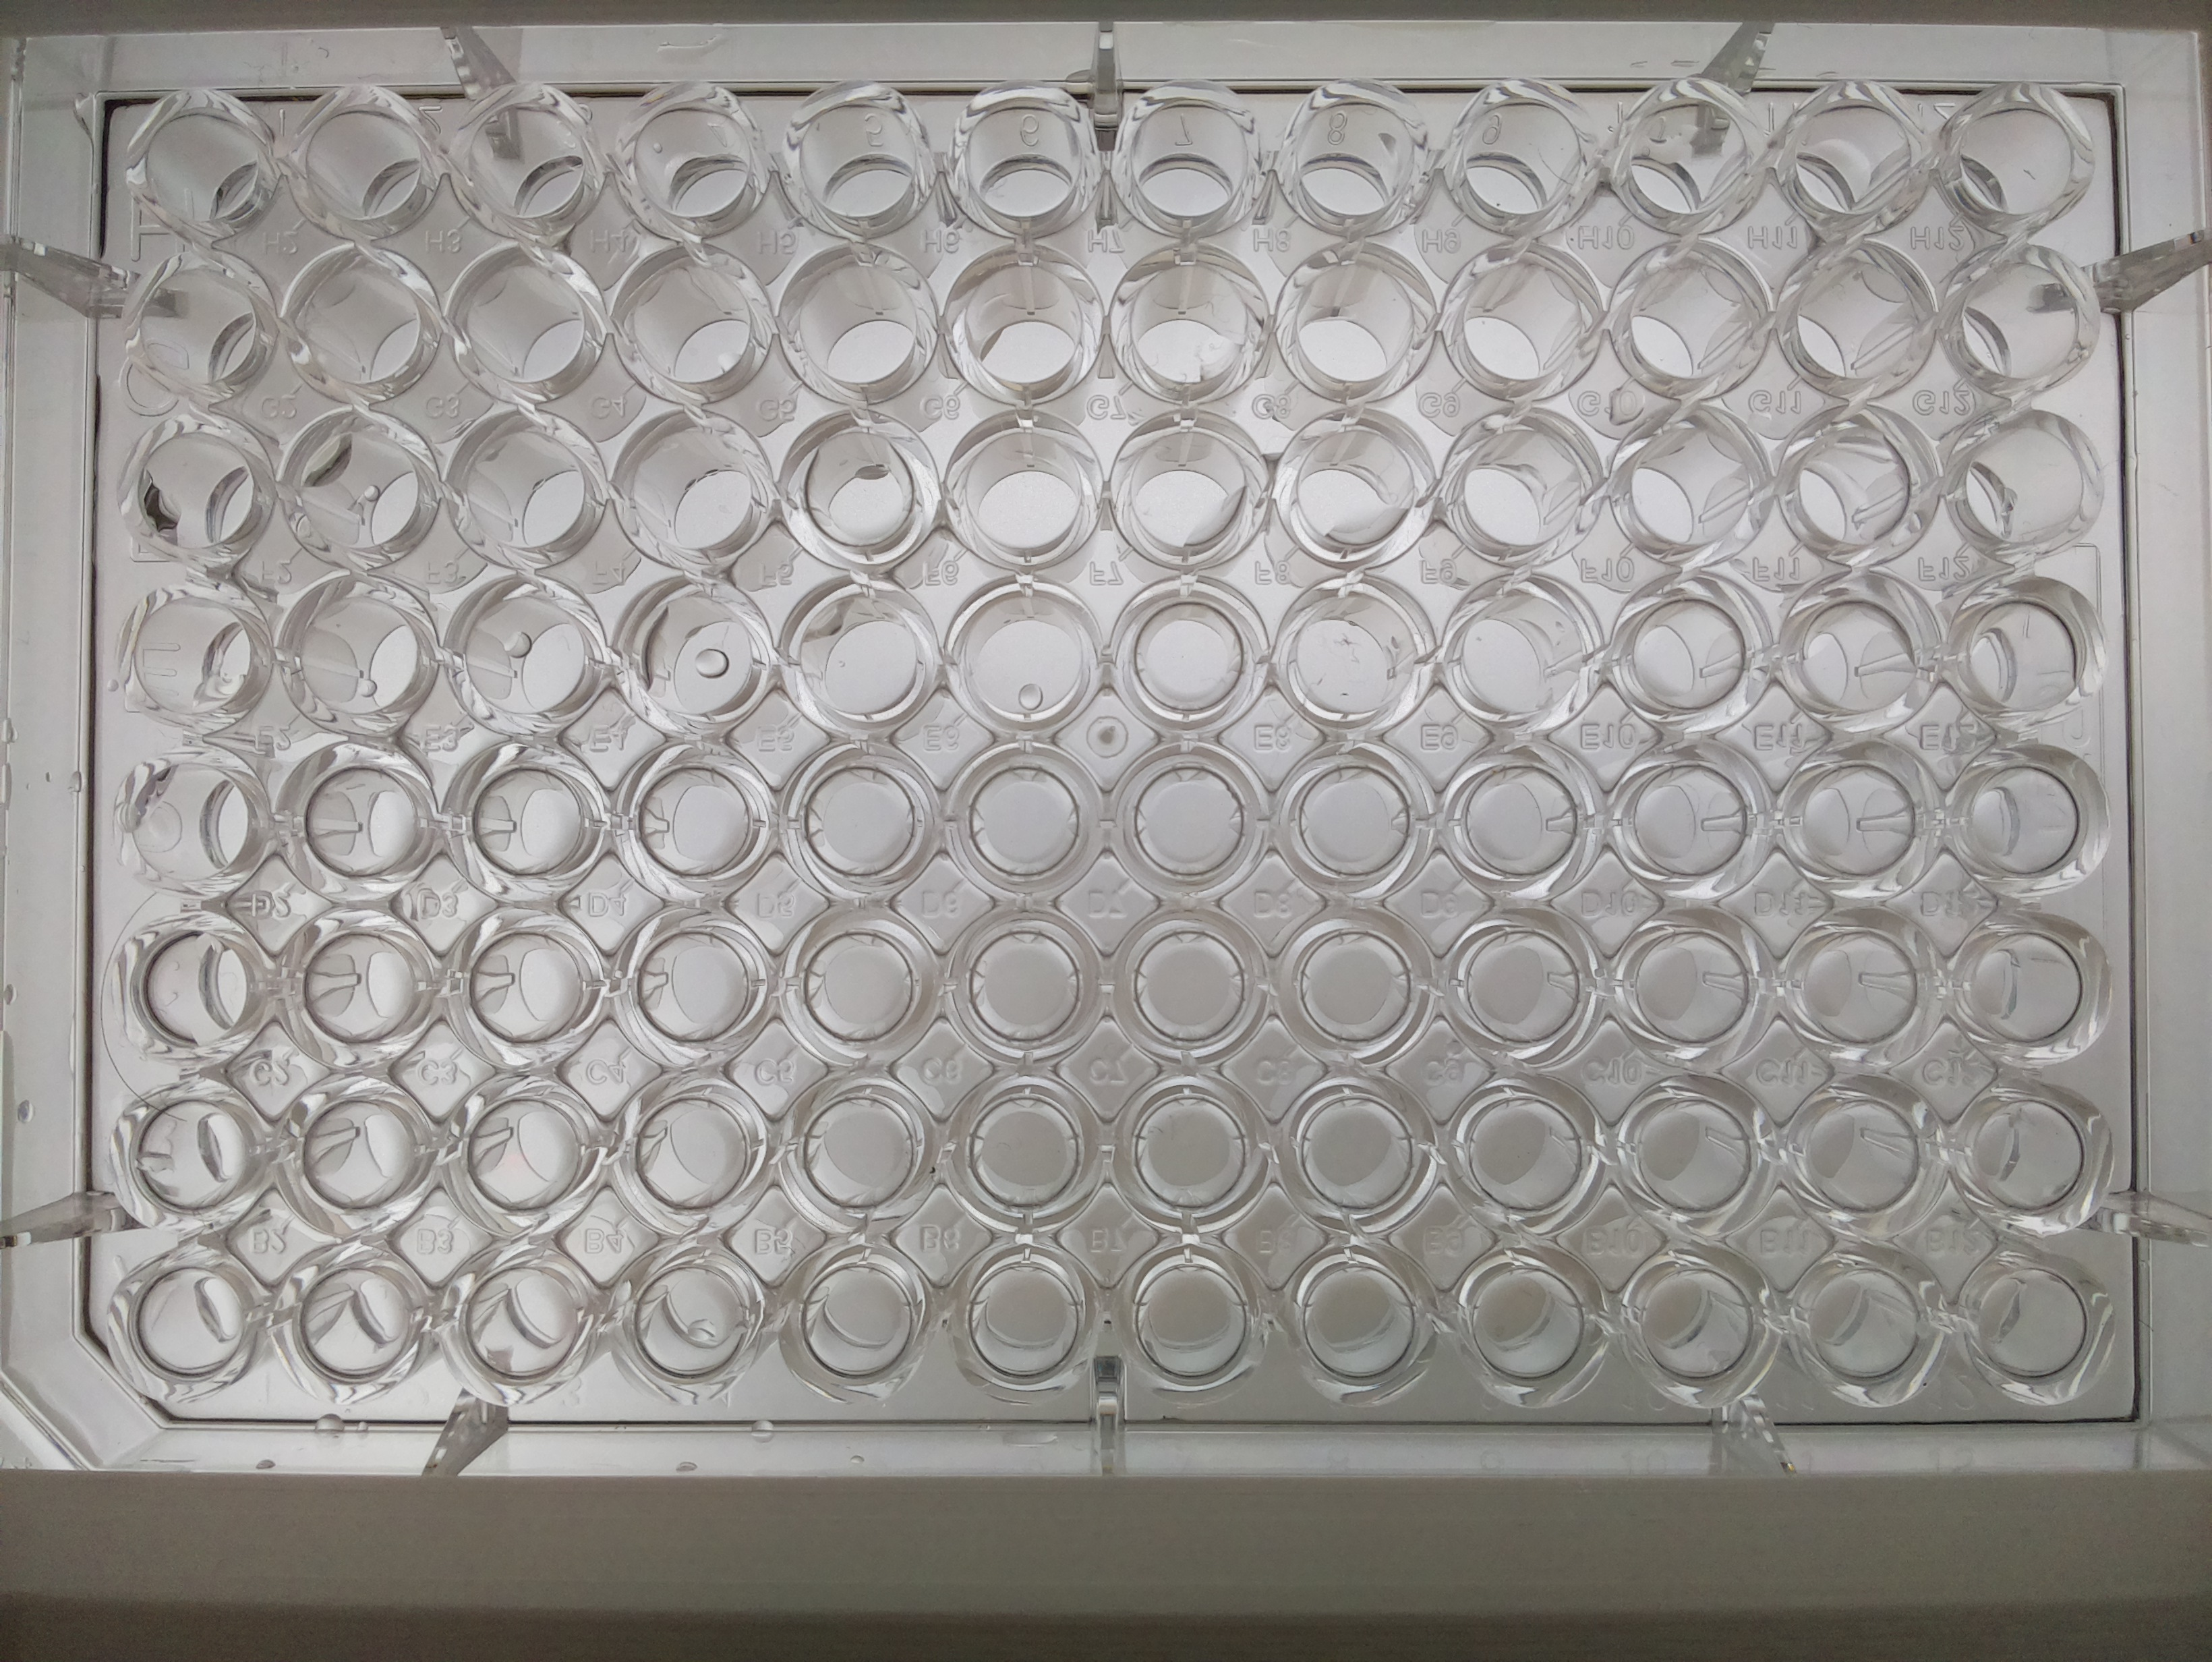

Image captured
Image saved .jpg
None


In [98]:
async def capture_photo(counter):
    uri = "ws://172.28.236.86:8765"
    
    async with websockets.connect(uri, max_size=5_000_000) as websocket:
        # send command to capture
        await websocket.send("capture")
        
        # wait for response
        response = await websocket.recv()
        
        try:
            # decode from Base64
            img_data = base64.b64decode(response)
            
            display(IPythonImage(data=img_data, format='jpg'))
            print("Image captured")

            with open(f"images/{counter}.jpg", "wb") as f:
                f.write(img_data)
            print("Image saved .jpg")

        except Exception as e:
            print("Response:", response)
            print("Exception:", e)

result = await capture_photo(counter=0)
print(result)

In [ ]:
counter = 0
image_path = f"images/{counter}.jpg"
# parameters for bilateral filtering
diameter = 5
sigmaColor = 75
sigmaSpace = 75

image_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
filtered_image = cv2.bilateralFilter(image_gray, diameter, sigmaColor, sigmaSpace)
image_rgb = cv2.imread(image_path)

rows = 8
cols = 12

top_left = (250, 250)
bottom_right = (2800, 2000)
# Add sliders to control the top-left and bottom-right positions
top_left_x = IntSlider(value=top_left[0], min=0, max=image_rgb.shape[1], description="Top Left X")
top_left_y = IntSlider(value=top_left[1], min=0, max=image_rgb.shape[0], description="Top Left Y")
bottom_right_x = IntSlider(value=bottom_right[0], min=0, max=image_rgb.shape[1], description="Bottom Right X")
bottom_right_y = IntSlider(value=bottom_right[1], min=0, max=image_rgb.shape[0], description="Bottom Right Y")

@interact(top_left_x=top_left_x, top_left_y=top_left_y, bottom_right_x=bottom_right_x, bottom_right_y=bottom_right_y)
def update_grid(top_left_x, top_left_y, bottom_right_x, bottom_right_y):
    # Update coordinates for top-left and bottom-right grid points
    top_left = (top_left_x, top_left_y)
    bottom_right = (bottom_right_x, bottom_right_y)

    x_step = (bottom_right[0] - top_left[0]) / (cols - 1)
    y_step = (bottom_right[1] - top_left[1]) / (rows - 1)

    expected_grid = []
    rgb_values = []

    for row in range(rows):
        for col in range(cols):
            x = int(top_left[0] + col * x_step)
            y = int(top_left[1] + row * y_step)
            expected_grid.append((x, y))

            # image[row, col] → image[y, x]
            b, g, r = image_rgb[y, x]
            rgb_values.append([r, g, b])

    output_grid = image_rgb.copy()

    # Draw circles
    for (x, y) in expected_grid:
        cv2.circle(output_grid, (x, y), 100, (255, 0, 0), 2)

    output_grid_rgb = cv2.cvtColor(output_grid, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 6))
    plt.imshow(output_grid_rgb)
    plt.axis("off")
    plt.title("Contour Detection")
    plt.show()


interactive(children=(IntSlider(value=250, description='Top Left X', max=3280), IntSlider(value=250, descripti…

background subtration

In [100]:
def image_rgb_extraction(image_path):
    # parameters for bilateral filtering
    diameter = 5
    sigmaColor = 75
    sigmaSpace = 75

    image_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    filtered_image = cv2.bilateralFilter(image_gray, diameter, sigmaColor, sigmaSpace)
    image_rgb = cv2.imread(image_path)

    rows = 8
    cols = 12

    # define coordinates for top-left and bottom-right grid points
    top_left = (265, 278)
    bottom_right = (2989, 2006)

    x_step = (bottom_right[0] - top_left[0]) / (cols - 1)
    y_step = (bottom_right[1] - top_left[1]) / (rows - 1)

    expected_grid = []
    new_rgb_values = []

    for row in range(rows):
        for col in range(cols):
            x = int(top_left[0] + col * x_step)
            y = int(top_left[1] + row * y_step)
            expected_grid.append((x, y))
            
            # image[row, col] → image[y, x]
            b, g, r = image_rgb[y, x]  
            new_rgb_values.append([r, g, b]) 

    output_grid = image_rgb.copy()

    # draw circle
    for (x, y) in expected_grid:
        cv2.circle(output_grid, (x, y), 100, (255, 0, 0), 2)

    output_grid_rgb = cv2.cvtColor(output_grid, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 6))
    plt.imshow(output_grid_rgb)
    plt.axis("off")
    plt.title("Contour Detection")
    plt.show()

    return new_rgb_values

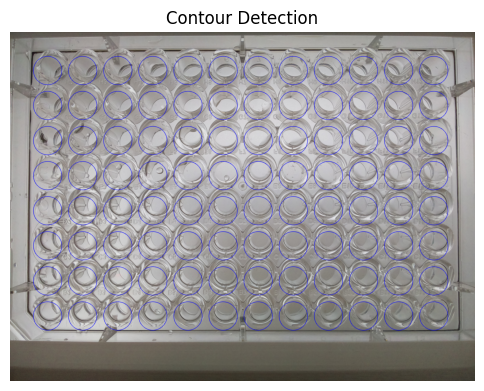

1st well: [np.uint8(193), np.uint8(193), np.uint8(193)]
2nd well: [np.uint8(188), np.uint8(188), np.uint8(186)]


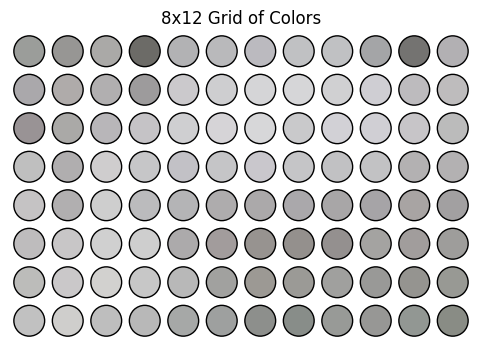

In [101]:
counter = 0
rgb_values = image_rgb_extraction(f"images/{counter}.jpg")
fig, ax = plt.subplots(figsize=(6, 4))
# make sure to have exact number of rows and columns
if len(rgb_values) < rows * cols:
    rgb_values += [[0, 0, 0]] * (rows * cols - len(rgb_values))

for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        rgb = rgb_values[index]
        # normalize RGB values to [0, 1]
        color = [val / 255 for val in rgb]
        # note the y-coordinate is inverted for display.
        circle = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, facecolor=color, 
                            edgecolor='black', linewidth=1)
        ax.add_patch(circle)

print('1st well:', rgb_values[84])
print('2nd well:', rgb_values[72])

ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect('equal')
ax.axis('off') 
plt.title('8x12 Grid of Colors')
plt.show()


# Generate 5 samples as training data

In [243]:
from pyDOE import lhs

# Number of samples
num_samples = 8

np.random.seed(0)  # Set seed for reproducibility
# Generate 5D Latin Hypercube Sampling
lhs_samples = lhs(4, samples=num_samples)

# Convert to volumes
lhs_samples_volumes = lhs_samples / lhs_samples.sum(axis=1, keepdims=True)* 100

# Convert lhs_samples_volumes to a DataFrame
lhs_df = pd.DataFrame(lhs_samples_volumes, columns=["volC", "volM", "volY", "volK"]).round(1)
lhs_df

,volC,volM,volY,volK
0,38.0,15.2,34.8,12.0
1,8.7,24.0,37.5,29.8
2,24.4,50.8,21.0,3.7
3,33.4,9.0,26.1,31.5
4,5.9,51.7,15.4,27.1
5,24.6,5.9,5.0,64.5
6,16.2,26.7,29.2,27.9
7,39.2,30.2,14.5,16.1


In [105]:
# Define Counter
counter = 1

# Increments of a 96 well plate
cell = [f"{chr(col)}{row}" for col in range(ord('A'), ord('H') + 1) for row in range(1, 13)]
# Generate IDs and wells for the new samples
lhs_df["id"] = range(counter, counter + len(lhs_df))
lhs_df["well"] = cell[counter-1::12][:len(lhs_df)]

# Reorder columns to match the existing CSV structure
lhs_df = lhs_df[["id", "well", "volC", "volM", "volY", "volK"]]

# csv_path = "opentron_shared/conditions.csv"
csv_save = "opentron_shared/conditions_save.csv"
# Save the updated DataFrame to the CSV files
# lhs_df.to_csv(csv_path, index=False)
lhs_df.to_csv(csv_save, mode='a', header=False, index=False)


># Mara --> Sample lhs_data in Mara
## Run this in terminal on Shared Folder

```
cd: Mara_shared
python -m http.server 8000
```

This will open a sever to allow opentron to acess the file from: 

csv_path = "http://192.168.0.100:8000/conditions.csv"   if on Mara Laptop\
local_path = "http://127.0.0.1:8000/conditions.csv" if on local Laptop

# Capture Image and convert to RGB

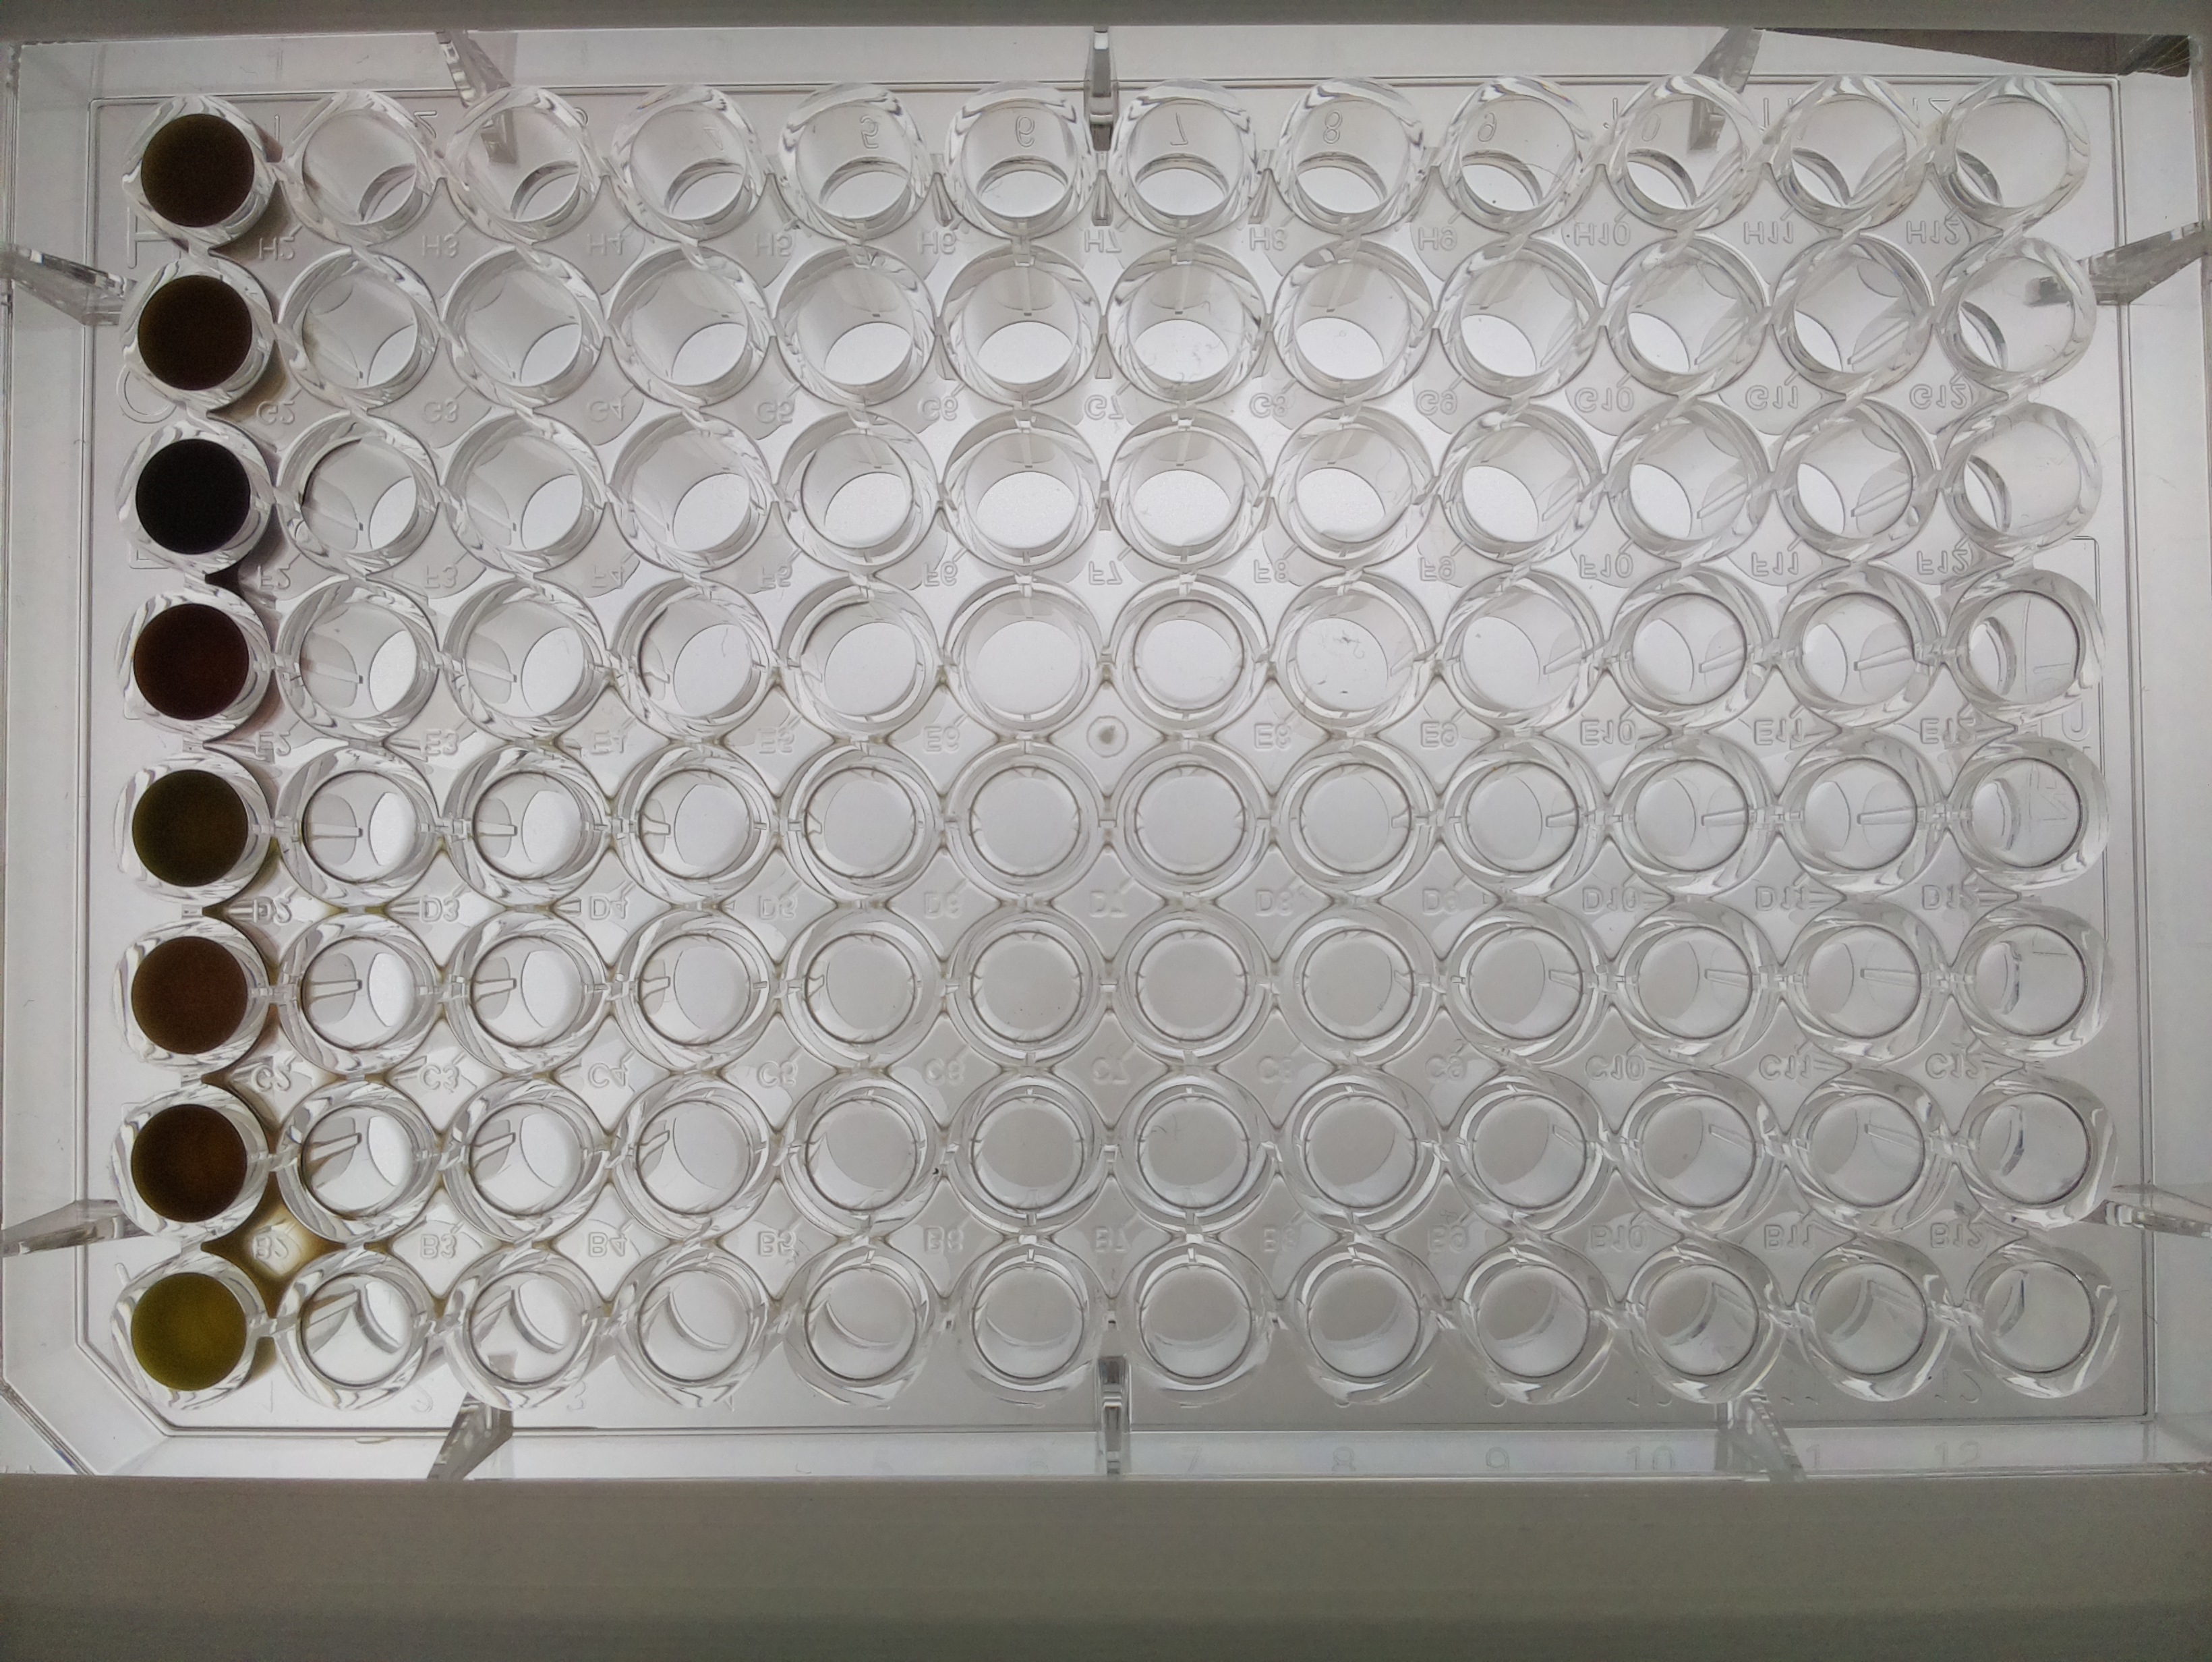

Image captured
Image saved .jpg
None


In [106]:
counter = 1
result = await capture_photo(counter)
print(result)

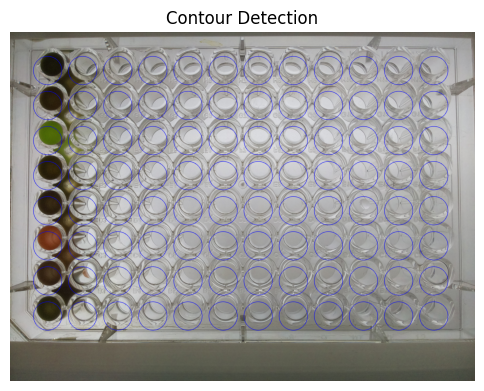

array([[ 35,  33,  12],
       [ 48,  31,  15],
       [104,  43,  15],
       [ 36,  24,  10],
       [ 40,  32,  13],
       [ 71,  97,   6],
       [ 38,  29,  12],
       [ 25,  23,  11]], dtype=uint8)

In [341]:
counter = 'may7_1'
image_path = f'images/{counter}.jpg'
new_rgb_values = np.array(image_rgb_extraction(image_path)[0::12])[::-1]
new_rgb_values

# Start of Color Iterations!


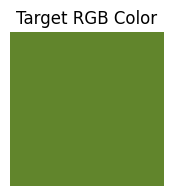

In [342]:
plt.figure(figsize=(2, 2))
#[97, 133, 44]
plt.imshow([[(97 / 255, 133 / 255, 44 / 255)]])
plt.axis("off")
plt.title("Target RGB Color")
plt.show()

In [343]:
import pandas as pd

# Define the data
data = [
    [9, "A1", 32.9, 2.8, 21.1, 43.2],
    [10, "B1", 33.5, 50.2, 12.4, 3.9],
    [11, "C1", 15.4, 70.7, 13.9, 0.1],
    [12, "D1", 29.3, 25.3, 20.9, 24.5],
    [13, "E1", 7.3, 11.0, 42.2, 39.6],
    [14, "F1", 51.5, 0.0, 48.5, 0.0],
    [15, "G1", 20.0, 26.5, 25.7, 27.8],
    [16, "H1", 29.0, 1.6, 26.8, 42.5],
]

# Create the DataFrame
df_may7_1 = pd.DataFrame(data, columns=["id", "well", "volC", "volM", "volY", "volK"])

# Display the DataFrame
print(df_may7_1)

   id well  volC  volM  volY  volK
0   9   A1  32.9   2.8  21.1  43.2
1  10   B1  33.5  50.2  12.4   3.9
2  11   C1  15.4  70.7  13.9   0.1
3  12   D1  29.3  25.3  20.9  24.5
4  13   E1   7.3  11.0  42.2  39.6
5  14   F1  51.5   0.0  48.5   0.0
6  15   G1  20.0  26.5  25.7  27.8
7  16   H1  29.0   1.6  26.8  42.5


In [344]:
def objective(rgb_list):
    target_rgb = np.array([97, 133, 44])  # Example target RGB
    rgb_list = np.array(rgb_list)
    return np.linalg.norm(rgb_list - target_rgb, axis=1)

In [355]:
import torch
# Set up the training data and bounds from LHS samples 
train_x = torch.tensor(df_may7_1[["volC", "volM", "volY", "volK"]].values)
train_y = torch.tensor(objective(new_rgb_values)).reshape(-1, 1)
og_bounds = torch.tensor([[0, 100], [0, 100], [0, 100], [0, 100]]).T

### Step 1:  Genearte new conditions with GP + BO

In [363]:
# make a gaussian process model
gp_model = GaussianProcess(train_X=train_x, train_y=train_y, bounds=og_bounds)
gp_model.fit()
print(train_x.shape)
# run the optimization to get new conditions
bo = BayesianOptimization(gp_model, og_bounds, batch_size=8, seed = 0)
conditions = bo.suggest_next_point()

def constrain_volumes(candidates):
    max_volume = 100
    df_candidates = candidates.copy()
    stoichiometry = df_candidates[["volC", "volM", "volY", "volK"]].div(df_candidates[["volC", "volM", "volY", "volK"]].sum(axis=1), axis=0)
    df_candidates[["volC", "volM", "volY", "volK"]] = stoichiometry.mul(max_volume, axis=0)
    df_volumes = df_candidates
    return df_volumes.round(1)
    
conditions_volumes = constrain_volumes(conditions)
#print(conditions.round(1))
print(conditions_volumes)


(8, 4)
   volC  volM  volY  volK
0  20.5  10.4  52.5  16.6
1   3.1   0.0  50.6  46.2
2   0.0   0.0  32.4  67.6
3   0.0  20.3  30.2  49.5
4  30.7   3.4  39.0  26.9
5   0.0   4.9  60.3  34.8
6  17.9   1.1  68.0  13.1
7   0.0   0.0  34.7  65.3


### Step 2: Add the new color into the CSV file and run Mara
>-  Prompt Mara to Start:  New row added
>-  Prompt Mara to Stop:  "ID" == exit


In [364]:
# MUST UPDATE COUNTER
counter = 2

In [365]:
next_condition = conditions_volumes

# Generate IDs and wells for the new samples
next_condition["id"] = range(len(train_x)+1,  len(train_x)+len(conditions_volumes)+1)
next_condition["well"] = cell[counter-1::12][:len(lhs_df)]

# Reorder columns to match the existing CSV structure
df_save =  next_condition[["id", "well", "volC", "volM", "volY", "volK"]]

df_save.to_csv(csv_save, mode='a', header = False, index=False)

### Mara will automatically run when a new conditions is added

### Step 3: Capture next image once Mara is finished

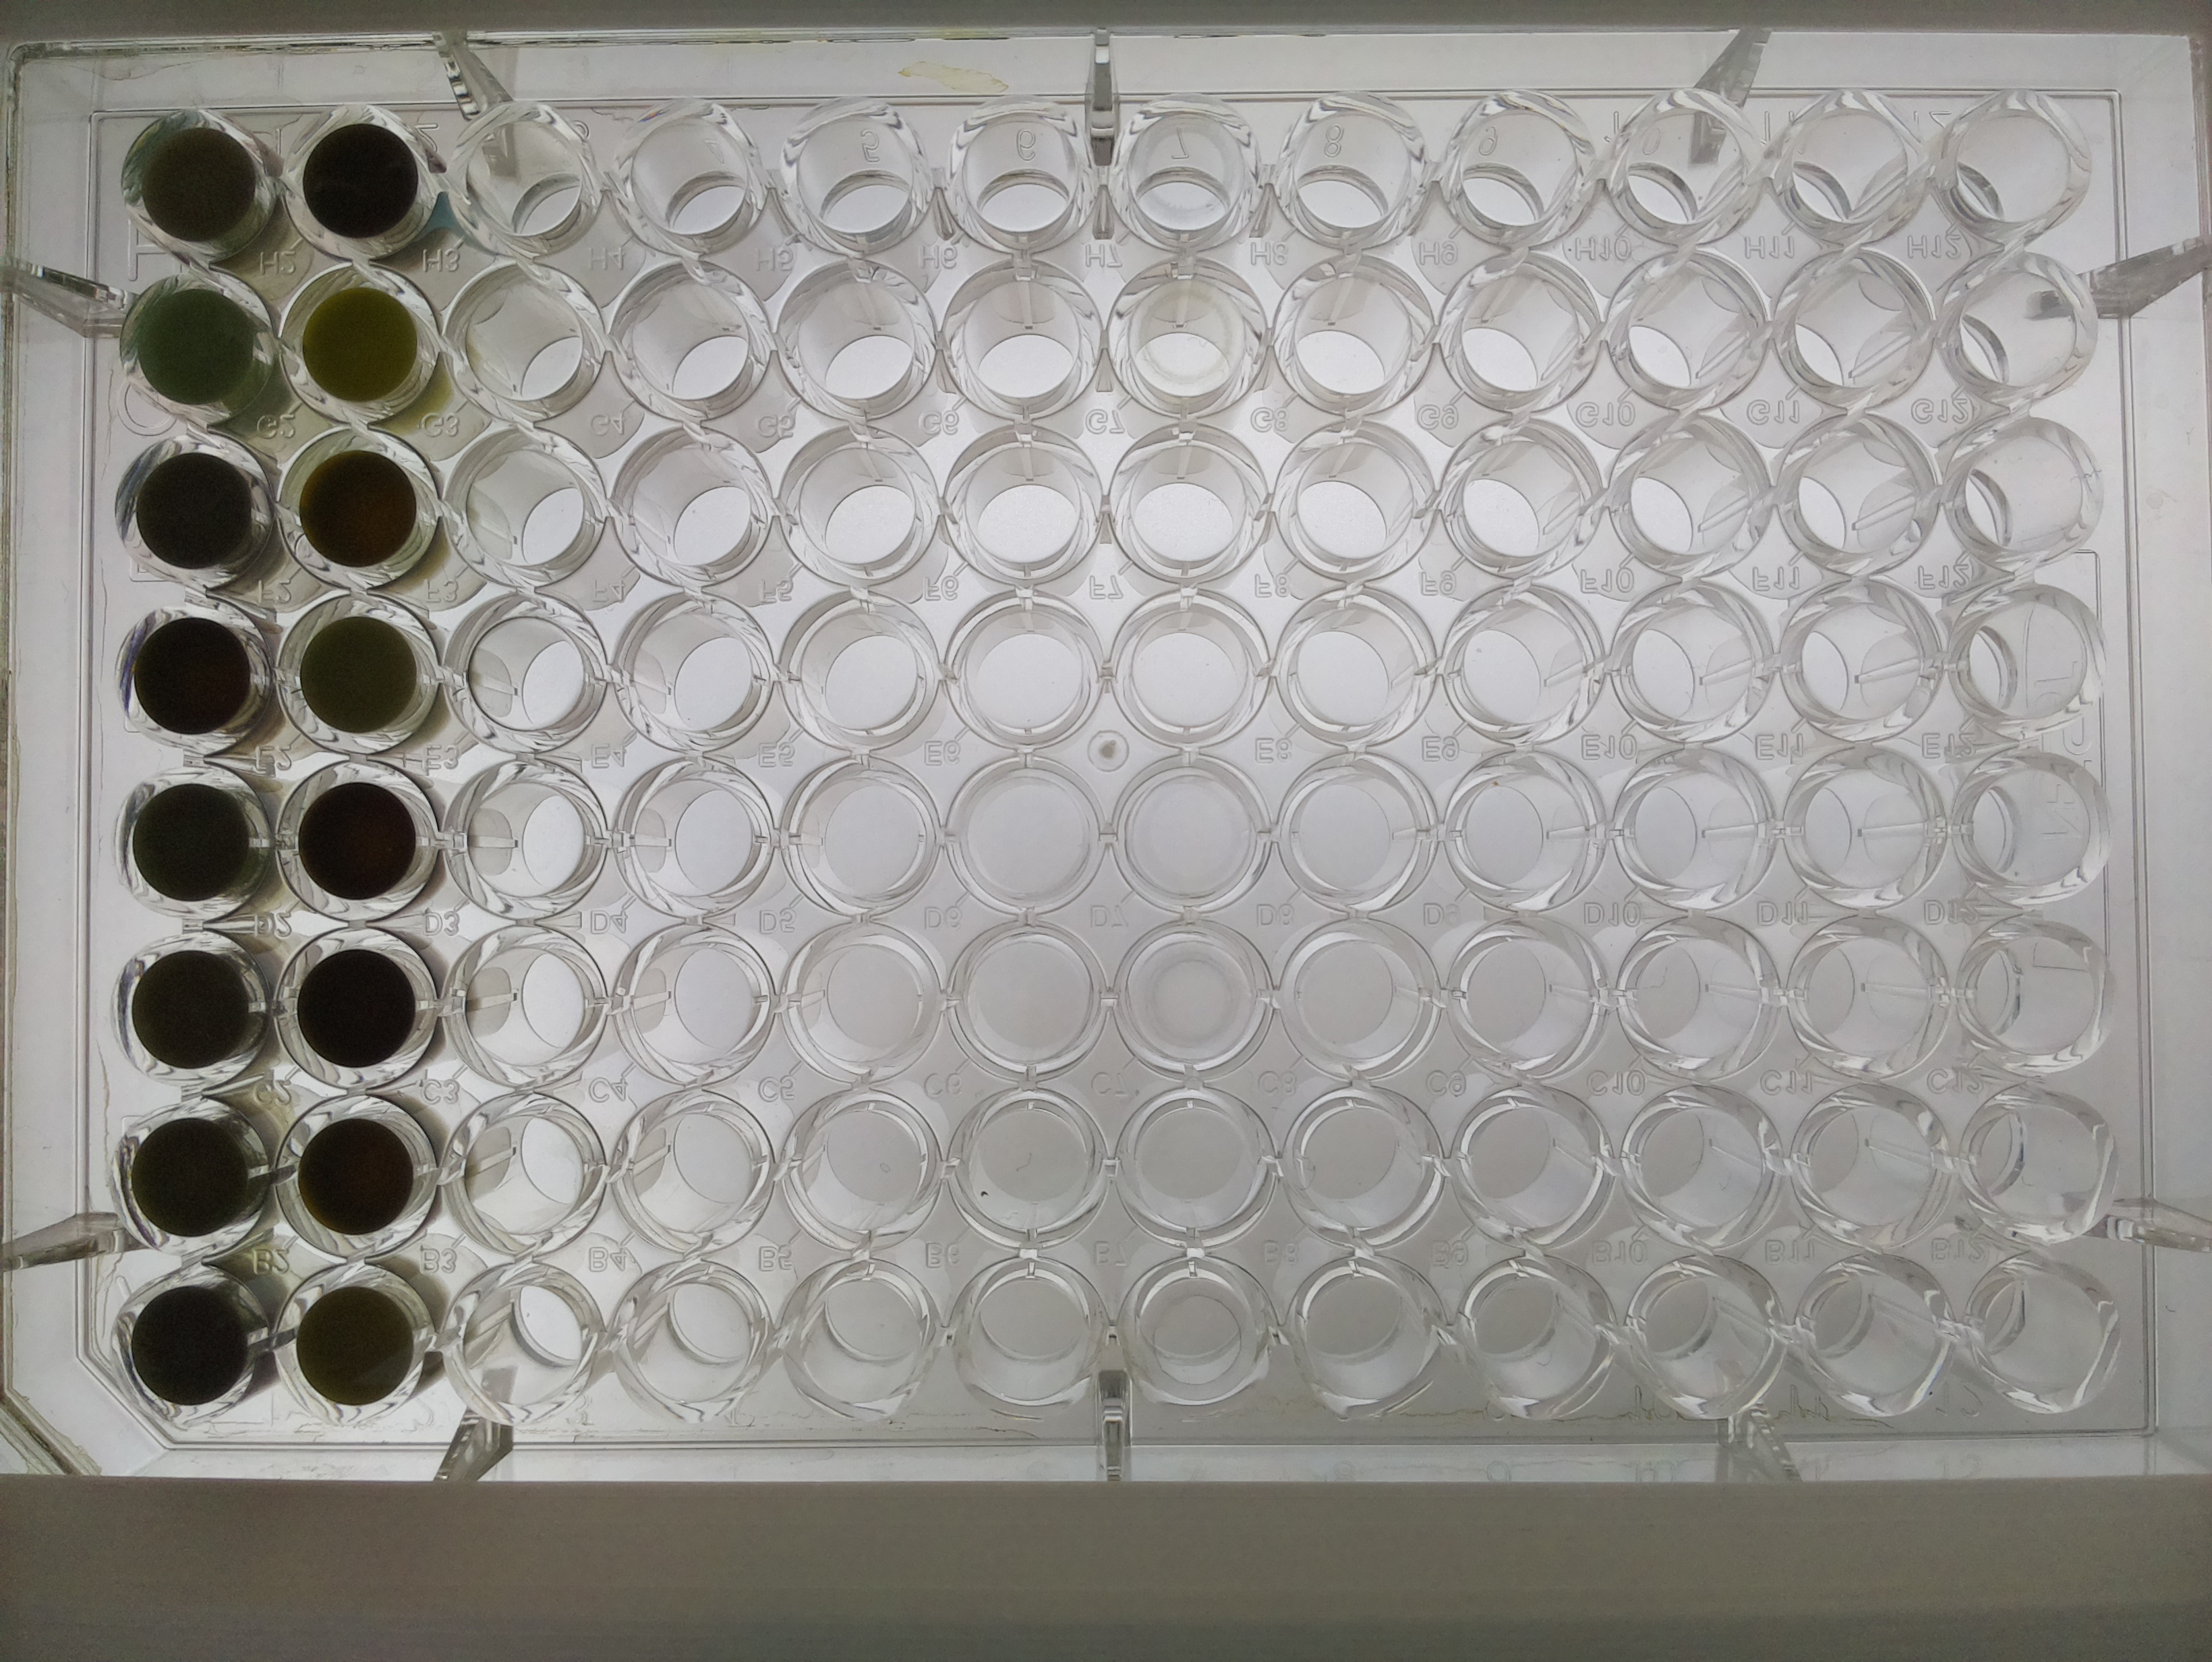

Image captured
Image saved .jpg
None


In [367]:
result = await capture_photo(counter)
print(result)

### Step 4: Extract the new RGB values and update the training data

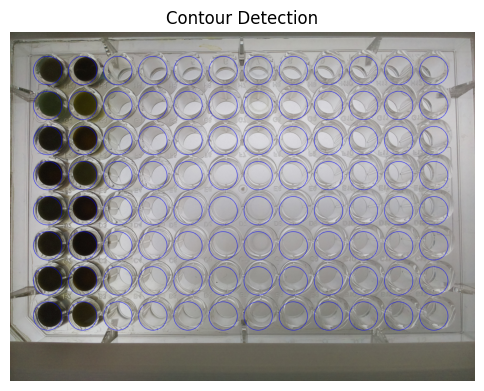

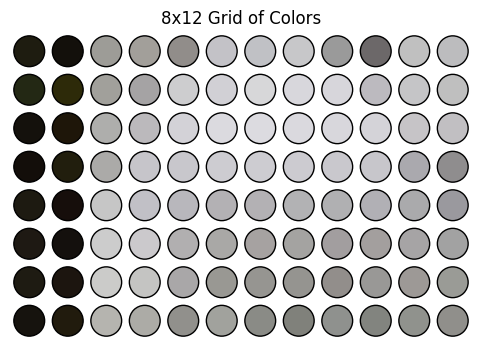

[127.64403629 134.70708964 143.45382532 144.48183277 125.16389256
 134.2944526  110.49886877 144.43683741]


In [368]:
image_path = f'images/{counter}.jpg'
new_rgb_values = image_rgb_extraction(image_path)

fig, ax = plt.subplots(figsize=(6, 4))

# make sure to have exact number of rows and columns
if len(rgb_values) < rows * cols:
    new_rgb_values += [[0, 0, 0]] * (rows * cols - len(new_rgb_values))

for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        rgb = new_rgb_values[index]
        # normalize RGB values to [0, 1]
        color = [val / 255 for val in rgb]
        # note the y-coordinate is inverted for display.
        circle = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, facecolor=color, 
                            edgecolor='black', linewidth=1)
        ax.add_patch(circle)


# print(rgb_values)
ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect('equal')
ax.axis('off') 
plt.title('8x12 Grid of Colors')
plt.show()

newest_rgb_values = np.array(new_rgb_values[counter-1::12])[::-1]
print(objective(newest_rgb_values))


In [369]:
new_x = next_condition[['volC', 'volM', 'volY', 'volK']].to_numpy()
old__x = train_x[:(counter-1)*8]
new_y = objective(newest_rgb_values).reshape(-1, 1)
old_y = train_y[:(counter-1)*8]

train_x = np.concatenate((old__x, new_x), axis=0)
train_y = np.concatenate((old_y, new_y), axis=0)
print(train_x.shape, train_y.shape)

(16, 4) (16, 1)


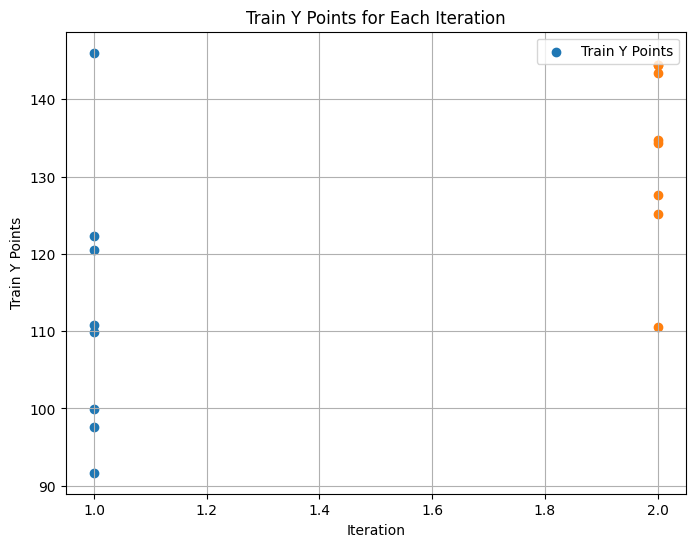

In [370]:
plt.figure(figsize=(8, 6))
iteration = range(1, counter + 1)  # Iteration count
for i in range(len(iteration)):
    y_points = train_y[i * 8:(i + 1) * 8]  # Extract points for each iteration
    plt.scatter([iteration[i]] * len(y_points), y_points, label=f"Iteration {iteration[i]}" if i == 0 else None)

plt.xlabel("Iteration")
plt.ylabel("Train Y Points")
plt.title("Train Y Points for Each Iteration")
plt.legend(["Train Y Points"], loc="upper right")
plt.grid(True)
plt.show()

ValueError: x and y must have same first dimension, but have shapes (5,) and (3,)

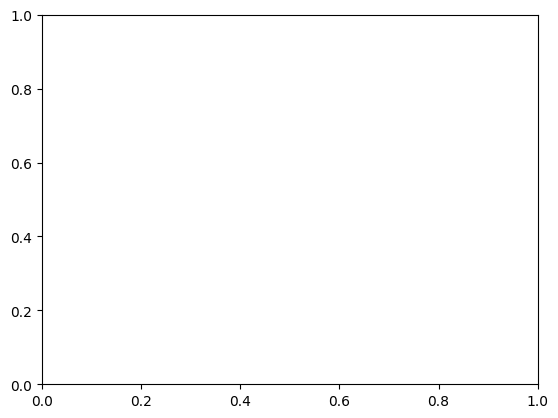

In [ ]:
# iteration = range(1,counter+1) # 1 is LHS, 2 onward is BO
# min_values = [train_y[i:i+8].min() for i in range(0, len(train_y), 8)]
# plt.plot(iteration,min_values,'.-')


### Step 5: Iterate! 
- update teh counter and Run Step 1 trought 5 until target reached